# Measure B

From `FINDINGS.md`:

> Establishing a Municipal Finance Corporation and a Public Bank. Yes 169,415, No 152,252. The yes share is 52.7 percent. On the November 4 report, No still led, by 144 votes, at 49.96 percent yes.
>
> Precinct shares run from 39.3 percent to 53.4 percent to 65.5 percent. The yes vote is stronger in the center and the east, and weaker on the west side and in District 2 in the north. District 9 is 64.3 percent yes and District 5 is 62.3 percent. District 10 is 55.8 percent and District 8 is 54.2 percent. District 2 is 41.3 percent, District 4 is 46.1 percent, and District 7 is 46.2 percent. The spread from District 2 to District 9 is 23.0 points.
>
> The yes share rises with the Hispanic share of the precinct (r = 0.55) and with the renter share (r = 0.43). It is lower where the share of households at $150,000 or more is higher (r = −0.45). The foreign-born share barely moves with it (r = 0.08).

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Citywide result

In [2]:
city = sf.citywide(data, "measure_b__yes", "measure_b__no")
city

{'measure_b__yes': 169415,
 'measure_b__no': 152252,
 'share_pct': 52.66782106961547,
 'margin': 17163}

## Precinct and supervisor-district geography

In [3]:
share, votes = sf.two_way(data, "measure_b__yes", "measure_b__no")
enough = data["ballots"] >= sf.MIN_BALLOTS
districts = sf.by_district(data, "measure_b__yes", "measure_b__no")
print("Precinct range, 10th / 50th / 90th percentile:", [round(v, 1) for v in sf.percentile_range(share, enough)])
districts.round(1).to_frame("Yes share, percent")

Precinct range, 10th / 50th / 90th percentile: [np.float64(39.3), np.float64(53.4), np.float64(65.5)]


,"Yes share, percent"
Supervisorial,
1,50.70
2,41.30
3,53.30
4,46.10
5,62.30
6,53.90
7,46.20
8,54.20
9,64.30


In [4]:
check.number("Yes votes", 169415, city["measure_b__yes"], 0)
check.number("No votes", 152252, city["measure_b__no"], 0)
check.number("Yes share, percent", 52.7, city["share_pct"])
for name, memo, value in zip(["10th", "50th", "90th"], [39.3, 53.4, 65.5], sf.percentile_range(share, enough)):
    check.number(f"Precinct share, {name} percentile", memo, value)
check.number("Yes share, District 9", 64.3, districts[9])
check.number("Yes share, District 5", 62.3, districts[5])
check.number("Yes share, District 10", 55.8, districts[10])
check.number("Yes share, District 8", 54.2, districts[8])
check.number("Yes share, District 2", 41.3, districts[2])
check.number("Yes share, District 7", 46.2, districts[7])
check.number("Yes share, District 4", 46.1, districts[4])
check.fact("Highest and lowest district", "District 9 and District 2",
           f"District {districts.idxmax()} and District {districts.idxmin()}",
           (districts.idxmax(), districts.idxmin()) == (9, 2))
check.number("Spread from District 2 to District 9, points", 23.0, districts.max() - districts.min())

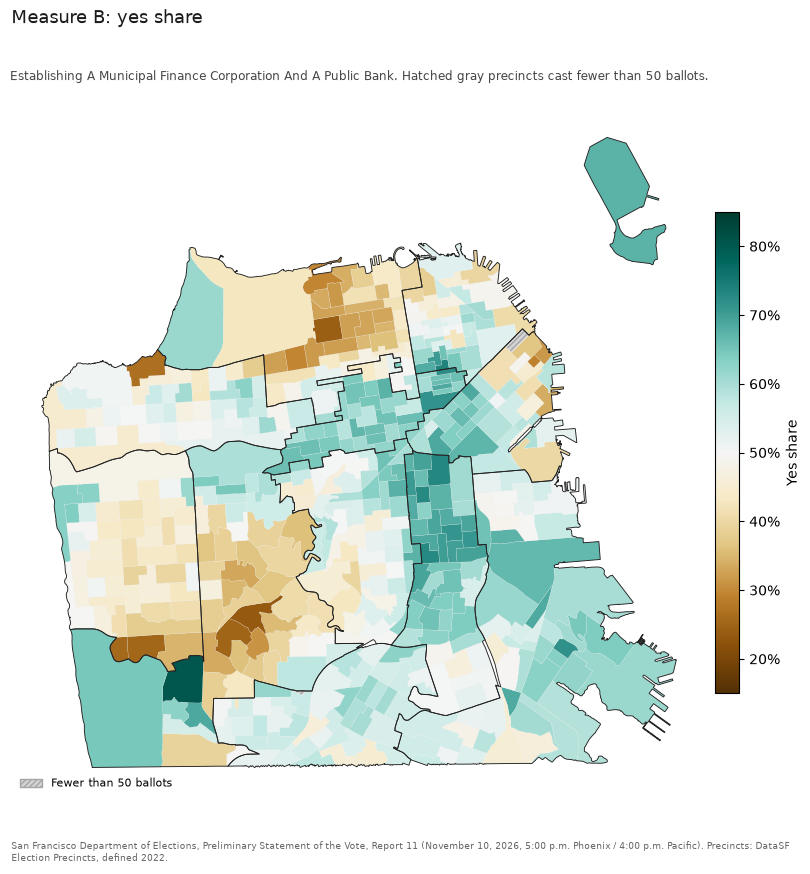

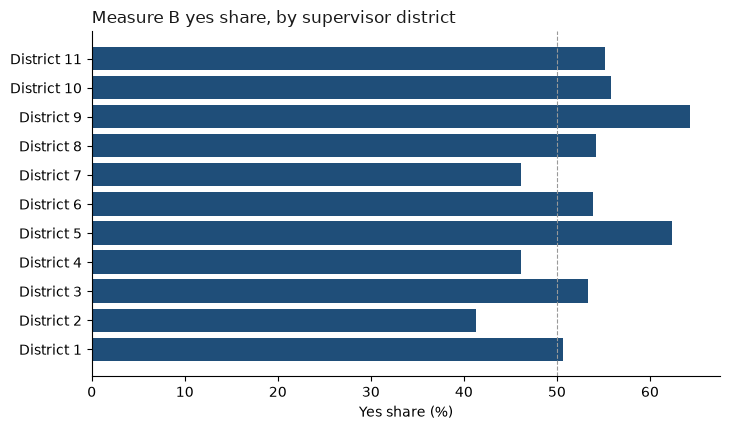

In [5]:
sf.rate_map(data, share, votes, "Measure B: yes share",
            "Establishing A Municipal Finance Corporation And A Public Bank. Hatched gray precincts cast fewer than 50 ballots.",
            "Yes share")
sf.district_bars(data.assign(weight=votes, share=share), "share", None,
                 "Measure B yes share, by supervisor district", "Yes share (%)");

## The November 4 report

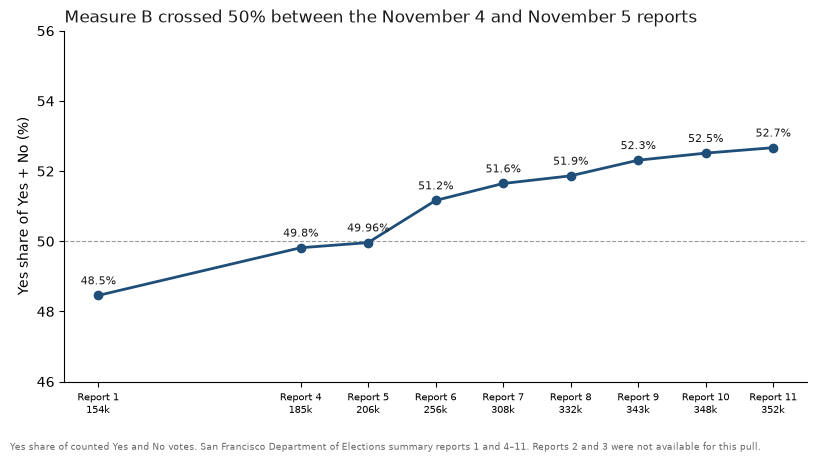

,choice,NO,YES,yes_pct
report,folder,,,
1,20261103_1,"73,858.00","69,434.00",48.46
4,20261103_4,"85,805.00","85,175.00",49.82
5,20261104,"95,366.00","95,222.00",49.96
6,20261105,"115,401.00","120,900.00",51.16
7,20261106,"137,078.00","146,415.00",51.65
8,20261107,"147,159.00","158,565.00",51.87
9,20261108,"149,904.00","164,430.00",52.31
10,20261109,"151,353.00","167,369.00",52.51
11,20261110,"152,252.00","169,415.00",52.67


In [6]:
trend = pd.read_csv(ROOT / "source" / "citywide_trend.csv")
b = trend[trend["contest"] == "Measure B"].pivot_table(index=["report", "folder"], columns="choice", values="votes")
b["yes_pct"] = 100 * b["YES"] / (b["YES"] + b["NO"])
nov4 = b.xs("20261104", level="folder").iloc[0]
check.number("No lead on the November 4 report, votes", 144, nov4["NO"] - nov4["YES"], 0)
check.number("Yes share on the November 4 report, percent", 49.96, nov4["yes_pct"], 2)
sf.line_chart(trend, None)
b

## Census comparison

,r
Non-Hispanic Asian,-0.16
Non-Hispanic white,-0.28
Hispanic,0.55
Bachelor's degree or higher,-0.35
Renters,0.43
"Households at $150,000+",-0.45
Foreign born,0.08


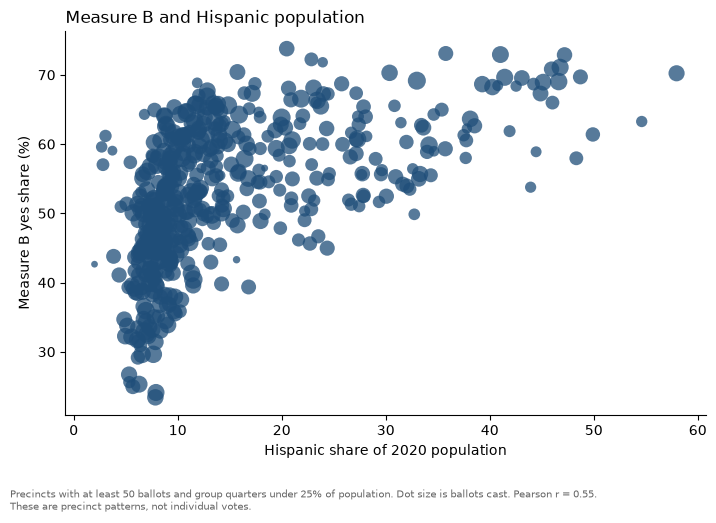

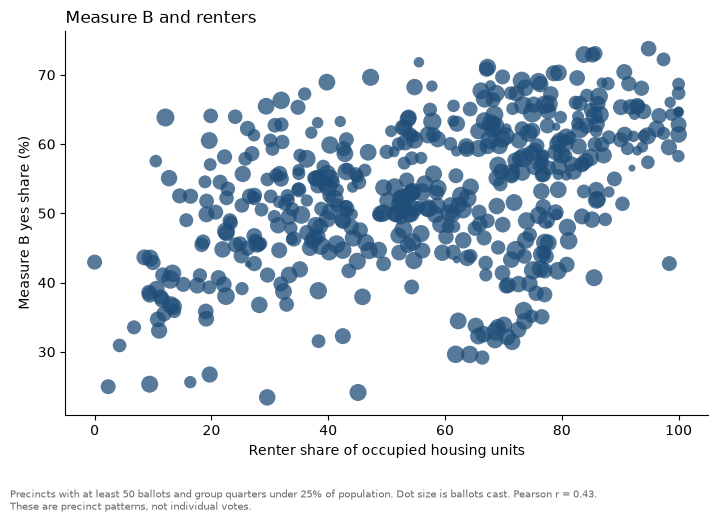

In [7]:
r = sf.census_correlations(data, share, sf.census_frame(data))
display(r.to_frame())
check.number("Correlation with Hispanic", 0.55, r["Hispanic"], 2)
check.number("Correlation with Renters", 0.43, r["Renters"], 2)
check.number("Correlation with Households at $150,000+", -0.45, r["Households at $150,000+"], 2)
check.number("Correlation with Foreign born", 0.08, r["Foreign born"], 2)
keep = sf.census_frame(data)
subset = data[keep].assign(share=share[keep])
sf.census_scatter(subset, "share", "hispanic_share", None, "Measure B and Hispanic population",
                  "Hispanic share of 2020 population", "Measure B yes share (%)")
sf.census_scatter(subset, "share", "renter_share", None, "Measure B and renters",
                  "Renter share of occupied housing units", "Measure B yes share (%)");

## Numbers the memo quotes

In [8]:
check.report();

,claim,memo,computed,matches
0,Yes votes,"169,415","169,415",yes
1,No votes,"152,252","152,252",yes
2,"Yes share, percent",52.7,52.7,yes
3,"Precinct share, 10th percentile",39.3,39.3,yes
4,"Precinct share, 50th percentile",53.4,53.4,yes
5,"Precinct share, 90th percentile",65.5,65.5,yes
6,"Yes share, District 9",64.3,64.3,yes
7,"Yes share, District 5",62.3,62.3,yes
8,"Yes share, District 10",55.8,55.8,yes
9,"Yes share, District 8",54.2,54.2,yes


All 21 numbers checked match the memo.
